# Train, evaluate and register with Pipeline 

Covers the benchmark, then one SageMaker Pipeline*that preprocesses the splits, trains XGBoost (with Debugger rules), evaluates it on the test split, gates on test macro-F1, registers the model, creates it, batch-transforms the production split and post-processes the probabilities into a predictions file. A publish cell then writes the stable reports (`xgboost_training.json`, `xgboost_eval.json`) from that execution, followed by the benchmark comparison, a manual approval sign-off and the model card.

In [22]:
from importlib.metadata import version, PackageNotFoundError
try:
    _sm_ver = version("sagemaker")
except PackageNotFoundError:
    _sm_ver = "0"
if int(_sm_ver.split(".")[0]) != 2:
    %pip uninstall -q -y sagemaker sagemaker-core sagemaker-train sagemaker-serve sagemaker-mlops
    %pip install -q "sagemaker>=2.200,<3"
    print(f"Replaced sagemaker {_sm_ver} with v2 - restarting kernel; re-run the notebook from the top.")
    import IPython
    IPython.Application.instance().kernel.do_shutdown(restart=True)
else:
    print("sagemaker", _sm_ver)

sagemaker 2.257.7


## Bootstrap

Path, config, boto3 session/clients and shared S3 helpers.

In [23]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import io, json
import boto3, numpy as np, pandas as pd
from src.pamap2.config import load_config, s3_uri
from src.pamap2.schema import ACTIVITY_NAMES
from src.pamap2 import evaluation as E

cfg = load_config()
session = boto3.Session(region_name=cfg["region"])

print("Caller:", session.client("sts").get_caller_identity()["Arn"])
s3 = session.client("s3")
SPLITS = s3_uri(cfg, "splits")
REPORTS = s3_uri(cfg, "models", "reports/")

def split_key(uri):
    b, k = uri[len("s3://"):].split("/", 1)
    return b, k
def read_parquet(name):
    b, k = split_key(SPLITS + name)
    return pd.read_parquet(io.BytesIO(s3.get_object(Bucket=b, Key=k)["Body"].read()))
def read_json(uri):
    b, k = split_key(uri)
    return json.loads(s3.get_object(Bucket=b, Key=k)["Body"].read())
def write_json(uri, obj):
    b, k = split_key(uri)
    s3.put_object(Bucket=b, Key=k, Body=json.dumps(obj, indent=2).encode())
    print("Wrote", uri)

FEATURES = read_json(SPLITS + "feature_columns.json")
LABEL_MAP = E.load_label_map(read_json(SPLITS + "label_map.json"))   # class index -> activity_id
K = len(LABEL_MAP)
CLASSES = list(range(K))
def class_name(i):
    return ACTIVITY_NAMES[LABEL_MAP[int(i)]]
print(K, "classes;", len(FEATURES), "features")

Caller: arn:aws:sts::887757489409:assumed-role/LabRole/SageMaker
18 classes; 128 features


In [24]:
import sagemaker
sm = session.client("sagemaker")
sm_session = sagemaker.Session(boto_session=session)
ROLE = cfg["role_arn"]
BUCKET = cfg["bucket"]
PIPE_PREFIX = "models/pipeline"

## Benchmark

Simple baseline: a depth-3 decision tree (scikit-learn, trained locally) on two features - chest acc16 magnitude std and HR mean (NaN filled with train median). A majority-class row is reported as the floor. Primary metric: macro-F1 on test. Test scores are optimistic (seen subjects, per the data split).

### Load splits and fit

In [25]:
from src.pamap2.benchmark import BENCHMARK_FEATURES, fit_benchmark, predict_benchmark, predict_majority
train, val, test = (read_parquet(f"{n}.parquet") for n in ("train", "validation", "test"))
for df in (train, val, test):
    E.check_feature_columns(df, FEATURES)
model = fit_benchmark(train)
print("Features:", BENCHMARK_FEATURES, "| train medians:", model["medians"], "| majority class:", class_name(model["majority"]))

Features: ['chest_acc16_mag_std', 'hr_mean'] | train medians: {'chest_acc16_mag_std': 0.4756572520805625, 'hr_mean': 96.984375} | majority class: computer work


### Metrics on validation and test

In [26]:
report = {"features": BENCHMARK_FEATURES, "model": "DecisionTree(max_depth=3)",
          "label_map": {str(k): v for k, v in LABEL_MAP.items()}}
for name, df in (("validation", val), ("test", test)):
    for label, pred in (("tree", predict_benchmark(model, df)), ("majority", predict_majority(model, df))):
        report[f"{name}_{label}"] = E.classification_metrics(df["label"], pred, CLASSES)
summary = pd.DataFrame([{"split": s, "model": m, "macro_f1": report[f"{s}_{m}"]["macro_f1"],
                         "accuracy": report[f"{s}_{m}"]["accuracy"]}
                        for s in ("validation", "test") for m in ("tree", "majority")])
display(summary)

,split,model,macro_f1,accuracy
0,validation,tree,0.291380,0.446653
1,validation,majority,0.012116,0.122385
2,test,tree,0.284703,0.445607
3,test,majority,0.012116,0.122385


In [6]:
pc = report["test_tree"]["per_class"]
display(pd.DataFrame({class_name(k): v for k, v in pc.items()}).T)

,precision,recall,f1,support
lying,0.000000,0.000000,0.000000,67.0
sitting,0.000000,0.000000,0.000000,64.0
standing,0.000000,0.000000,0.000000,67.0
walking,0.567376,0.952381,0.711111,84.0
running,0.780488,1.000000,0.876712,32.0
cycling,0.564706,0.827586,0.671329,58.0
Nordic walking,0.623377,0.727273,0.671329,66.0
watching TV,0.000000,0.000000,0.000000,32.0
computer work,0.340361,0.965812,0.503341,117.0
car driving,0.000000,0.000000,0.000000,20.0


### Save report

In [27]:
write_json(REPORTS + "benchmark.json", report)

Wrote s3://pamap2-har-887757489409-us-east-1/models/reports/benchmark.json


## SageMaker Pipeline: preprocess, train, evaluate, gate, register, batch transform, post-process

One parametrized, reproducible pipeline (`pamap2-har-pipeline`) replaces the hand-run XGBoost train / evaluate / register / batch-transform cells. Training, evaluation, registration and batch transform happen **only** through the pipeline; later cells read its outputs.

1. **Preprocess** (`ml.m5.large`) - `src/pamap2/pipeline/preprocess.py` validates the split Parquet files from notebook 2 and emits XGBoost CSVs plus the production feature CSV.


2. **Train** (`ml.m5.xlarge`) - built-in XGBoost 1.7-1, `multi:softprob`, fixed hyperparameters, early stopping on validation; Debugger rules LossNotDecreasing, Overfit, ClassImbalance run beside the training step.


3. **Evaluate** (`ml.m5.large`) - `evaluate.py` writes `evaluation.json` and `test_predictions.csv` for the test split.


4. **Gate** - if test macro-F1 >= `MacroF1Threshold` (default 0.85): register as `PendingManualApproval`, create the model, batch-transform the production features and **post-process** (`ml.m5.large`, `postprocess.py`) the probabilities into `predictions.parquet`. Otherwise a `FailStep` ends the execution and nothing is registered, transformed or published.

Scoring is gated by macro-F1 only: batch transform and post-processing run in the same execution as registration, while the package is still `PendingManualApproval`. The manual approval cell further down stays a human sign-off.

### Pipeline session and parameters

In [28]:
import sagemaker
from sagemaker.workflow.pipeline_context import PipelineSession
from sagemaker.workflow.parameters import ParameterInteger, ParameterString, ParameterFloat
from sagemaker.workflow.functions import Join, JsonGet
from sagemaker.workflow.execution_variables import ExecutionVariables

pipeline_session = PipelineSession(boto_session=session, default_bucket=BUCKET, default_bucket_prefix=PIPE_PREFIX)

processing_instance_count = ParameterInteger(name="ProcessingInstanceCount", default_value=1)
training_instance_type = ParameterString(name="TrainingInstanceType", default_value="ml.m5.xlarge")
model_approval_status = ParameterString(name="ModelApprovalStatus", default_value="PendingManualApproval")
input_data = ParameterString(name="InputData", default_value=SPLITS)
macro_f1_threshold = ParameterFloat(name="MacroF1Threshold", default_value=0.85)

def pipe_s3(*parts):
    """s3://<bucket>/models/pipeline/<parts...> (parts may be pipeline variables)."""
    return Join(on="/", values=["s3:/", BUCKET, PIPE_PREFIX, *parts])

### Preprocess
`src/pamap2/pipeline/preprocess.py` validates the four split files (feature columns, labels `0..K-1`) and writes `train/`, `validation/`, `test/` CSVs (label first, no header) plus `batch/features.csv`.

In [29]:
from sagemaker.sklearn.processing import SKLearnProcessor
from sagemaker.processing import ProcessingInput, ProcessingOutput
from sagemaker.workflow.steps import ProcessingStep

sklearn_processor = SKLearnProcessor(
    framework_version="1.2-1", instance_type="ml.m5.large", instance_count=processing_instance_count,
    role=ROLE, sagemaker_session=pipeline_session)
exec_id = ExecutionVariables.PIPELINE_EXECUTION_ID
step_process = ProcessingStep(
    name="PreprocessSplits",
    step_args=sklearn_processor.run(
        inputs=[ProcessingInput(source=input_data, destination="/opt/ml/processing/input")],
        outputs=[ProcessingOutput(output_name=n, source=f"/opt/ml/processing/{n}",
                                  destination=pipe_s3("preprocess", exec_id, n))
                 for n in ("train", "validation", "test", "batch")],
        code=str(ROOT / "src/pamap2/pipeline/preprocess.py")))

INFO:sagemaker.image_uris:Defaulting to only available Python version: py3
/opt/conda/lib/python3.12/site-packages/sagemaker/workflow/pipeline_context.py:340: UserWarning: Running within a PipelineSession, there will be No Wait, No Logs, and No Job being started.
  warnings.warn(


### Train 
Built-in SageMaker XGBoost 1.7-1, `multi:softprob`, fixed hyperparameters, unweighted, early stopping on validation. 

Debugger rules: LossNotDecreasing, Overfit, ClassImbalance (`argmax` is set because `multi:softprob` saves per-class probabilities). Output and Debugger paths are under `models/pipeline/xgboost/`.

In [30]:
from sagemaker.estimator import Estimator
from sagemaker.inputs import TrainingInput
from sagemaker.workflow.steps import TrainingStep
from sagemaker.debugger import Rule, rule_configs, DebuggerHookConfig, CollectionConfig

image = sagemaker.image_uris.retrieve("xgboost", cfg["region"], cfg["xgboost_version"])
print(image)
estimator = Estimator(
    image_uri=image, role=ROLE, instance_count=1, instance_type=training_instance_type,
    output_path=f"s3://{BUCKET}/{PIPE_PREFIX}/xgboost/", sagemaker_session=pipeline_session,
    max_run=3600,
    debugger_hook_config=DebuggerHookConfig(
        s3_output_path=f"s3://{BUCKET}/{PIPE_PREFIX}/xgboost/debugger/",
        collection_configs=[CollectionConfig(name=n, parameters={"save_interval": "5"})
                            for n in ("metrics", "feature_importance", "average_shap",
                                      "labels", "predictions")]),
    rules=[Rule.sagemaker(rule_configs.loss_not_decreasing()),
           Rule.sagemaker(rule_configs.overfit()),
           Rule.sagemaker(rule_configs.class_imbalance(), rule_parameters={"argmax": "True"})])
estimator.set_hyperparameters(
    objective="multi:softprob", num_class=K, num_round=500, early_stopping_rounds=20,
    eval_metric="mlogloss,merror", max_depth=6, eta=0.1, subsample=0.8, colsample_bytree=0.8)
outs = step_process.properties.ProcessingOutputConfig.Outputs
step_train = TrainingStep(
    name="TrainModel",
    step_args=estimator.fit(inputs={
        "train": TrainingInput(s3_data=outs["train"].S3Output.S3Uri, content_type="text/csv"),
        "validation": TrainingInput(s3_data=outs["validation"].S3Output.S3Uri, content_type="text/csv")}))

INFO:sagemaker.image_uris:Ignoring unnecessary instance type: None.
INFO:sagemaker.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.


683313688378.dkr.ecr.us-east-1.amazonaws.com/sagemaker-xgboost:1.7-1


### Evaluate
`src/pamap2/pipeline/evaluate.py` loads the booster (`xgboost-model` from `model.tar.gz`), predicts the test CSV and writes `evaluation.json` (macro-F1 and accuracy in SageMaker model-quality format, per-class metrics, confusion matrix) and `test_predictions.csv` (label, predicted class, confidence) used later by the model-quality baseline.

In [31]:
from sagemaker.processing import ScriptProcessor
from sagemaker.workflow.properties import PropertyFile

script_eval = ScriptProcessor(
    image_uri=image, command=["python3"], instance_type="ml.m5.large", instance_count=1,
    role=ROLE, sagemaker_session=pipeline_session)
evaluation_report = PropertyFile(name="EvaluationReport", output_name="evaluation", path="evaluation.json")
step_eval = ProcessingStep(
    name="EvaluateModel",
    step_args=script_eval.run(
        inputs=[ProcessingInput(source=step_train.properties.ModelArtifacts.S3ModelArtifacts,
                                destination="/opt/ml/processing/model"),
                ProcessingInput(source=outs["test"].S3Output.S3Uri, destination="/opt/ml/processing/test")],
        outputs=[ProcessingOutput(output_name="evaluation", source="/opt/ml/processing/evaluation",
                                  destination=pipe_s3("evaluation", exec_id))],
        code=str(ROOT / "src/pamap2/pipeline/evaluate.py")),
    property_files=[evaluation_report])

### Create model, batch transform, post-process, register

In [32]:
from sagemaker.model import Model
from sagemaker.workflow.model_step import ModelStep

model = Model(image_uri=image, model_data=step_train.properties.ModelArtifacts.S3ModelArtifacts,
              sagemaker_session=pipeline_session, role=ROLE)
step_create_model = ModelStep(name="CreateModel", step_args=model.create(instance_type="ml.m5.large"))

In [33]:
from sagemaker.transformer import Transformer
from sagemaker.workflow.steps import TransformStep

transformer = Transformer(
    model_name=step_create_model.properties.ModelName, instance_count=1, instance_type="ml.m5.large",
    strategy="MultiRecord", assemble_with="Line", accept="text/csv",
    output_path=pipe_s3("transform-output", exec_id), sagemaker_session=pipeline_session)
step_transform = TransformStep(
    name="BatchTransform",
    step_args=transformer.transform(
        data=outs["batch"].S3Output.S3Uri, content_type="text/csv", split_type="Line"))

`src/pamap2/pipeline/postprocess.py` turns the raw probabilities into one predictions row per production window: predicted class, activity id (via `label_map.json`), activity name, intensity, confidence and the true activity id. Activity names and intensities are passed as a small JSON file written by the next cell. The step fails if the probability rows differ from the production rows, the column count differs from K, or a predicted activity is unknown.

In [34]:
from src.pamap2.schema import ACTIVITY_NAMES
from src.pamap2.features import intensity_of

activity_meta = {str(a): {"name": ACTIVITY_NAMES[a], "intensity": intensity_of(a)} for a in LABEL_MAP.values()}
write_json(f"s3://{BUCKET}/{PIPE_PREFIX}/config/activity_meta.json", activity_meta)
script_post = SKLearnProcessor(
    framework_version="1.2-1", instance_type="ml.m5.large", instance_count=1,
    role=ROLE, sagemaker_session=pipeline_session)
step_postprocess = ProcessingStep(
    name="PostProcessPredictions",
    step_args=script_post.run(
        inputs=[ProcessingInput(source=step_transform.properties.TransformOutput.S3OutputPath,
                                destination="/opt/ml/processing/transform"),
                ProcessingInput(source=input_data, destination="/opt/ml/processing/input"),
                ProcessingInput(source=f"s3://{BUCKET}/{PIPE_PREFIX}/config/activity_meta.json",
                                destination="/opt/ml/processing/meta")],
        outputs=[ProcessingOutput(output_name="predictions", source="/opt/ml/processing/predictions",
                                  destination=pipe_s3("predictions", exec_id))],
        code=str(ROOT / "src/pamap2/pipeline/postprocess.py")))

INFO:sagemaker.image_uris:Defaulting to only available Python version: py3


Wrote s3://pamap2-har-887757489409-us-east-1/models/pipeline/config/activity_meta.json


In [35]:
from sagemaker.model_metrics import MetricsSource, ModelMetrics

model_metrics = ModelMetrics(model_statistics=MetricsSource(
    s3_uri=Join(on="/", values=[step_eval.properties.ProcessingOutputConfig.Outputs["evaluation"].S3Output.S3Uri,
                                "evaluation.json"]),
    content_type="application/json"))
step_register = ModelStep(
    name="RegisterModel",
    step_args=model.register(
        content_types=["text/csv"], response_types=["text/csv"],
        inference_instances=["ml.m5.large"], transform_instances=["ml.m5.large"],
        model_package_group_name=cfg["model_package_group"], approval_status=model_approval_status,
        model_metrics=model_metrics, customer_metadata_properties={"source": "sagemaker-pipeline"},
        description="PAMAP2 activity recognition, multi:softprob (SageMaker Pipeline)"))

### Gate on test macro-F1
`>= MacroF1Threshold` registers, creates the model, batch-transforms and post-processes; otherwise `FailStep` (nothing registered, transformed or published).

In [36]:
from sagemaker.workflow.conditions import ConditionGreaterThanOrEqualTo
from sagemaker.workflow.condition_step import ConditionStep
from sagemaker.workflow.fail_step import FailStep

step_fail = FailStep(
    name="MacroF1BelowThreshold",
    error_message=Join(on=" ", values=["Test macro-F1 is below MacroF1Threshold", macro_f1_threshold]))
step_cond = ConditionStep(
    name="CheckMacroF1",
    conditions=[ConditionGreaterThanOrEqualTo(
        left=JsonGet(step_name=step_eval.name, property_file=evaluation_report,
                     json_path="multiclass_classification_metrics.macro_f1.value"),
        right=macro_f1_threshold)],
    if_steps=[step_register, step_create_model, step_transform, step_postprocess],
    else_steps=[step_fail])

### Pipeline definition and upsert
Creates the model package group if it does not exist yet, then creates or updates the pipeline (no duplicates on re-run).

In [37]:
from sagemaker.workflow.pipeline import Pipeline

pipeline = Pipeline(
    name=cfg["pipeline_name"],
    parameters=[processing_instance_count, training_instance_type, model_approval_status, input_data,
                macro_f1_threshold],
    steps=[step_process, step_train, step_eval, step_cond],
    sagemaker_session=pipeline_session)
definition = json.loads(pipeline.definition())
print([s["Name"] for s in definition["Steps"]])
print([p["Name"] for p in definition["Parameters"]])

INFO:sagemaker.image_uris:Ignoring unnecessary instance type: None.
INFO:sagemaker.image_uris:Ignoring unnecessary instance type: None.
INFO:sagemaker.image_uris:Ignoring unnecessary instance type: None.


['PreprocessSplits', 'TrainModel', 'EvaluateModel', 'CheckMacroF1']
['ProcessingInstanceCount', 'TrainingInstanceType', 'ModelApprovalStatus', 'InputData', 'MacroF1Threshold']


In [38]:
group = cfg["model_package_group"]
try:
    sm.describe_model_package_group(ModelPackageGroupName=group)
except sm.exceptions.ClientError as e:
    if "does not exist" not in str(e) and "ValidationException" not in str(e):
        raise
    sm.create_model_package_group(ModelPackageGroupName=group,
                                  ModelPackageGroupDescription="PAMAP2 HAR XGBoost models")
upsert_resp = pipeline.upsert(role_arn=ROLE)
print(upsert_resp["PipelineArn"])

INFO:sagemaker.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.


arn:aws:sagemaker:us-east-1:887757489409:pipeline/pamap2-har-pipeline


Starts one execution with default parameters: a processing job, a training job (plus Debugger rule jobs), an evaluation processing job and, if the gate passes, a transform job and a post-process job.

In [39]:
execution = pipeline.start()
print(execution.arn)
print(execution.describe()["PipelineExecutionStatus"])

INFO:sagemaker.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.


arn:aws:sagemaker:us-east-1:887757489409:pipeline/pamap2-har-pipeline/execution/jlqa6fgd20cq
Executing


In [41]:
try:
    execution.wait(delay=30, max_attempts=240)
except Exception as e:
    print("Execution did not succeed:", e)
print("Status:", execution.describe()["PipelineExecutionStatus"])

Status: Succeeded


In [42]:
import pandas as pd
steps = execution.list_steps()
pd.DataFrame([{"step": s["StepName"], "status": s["StepStatus"], "reason": s.get("FailureReason", "")[:120]}
              for s in reversed(steps)])

,step,status,reason
0,PreprocessSplits,Succeeded,
1,TrainModel,Succeeded,
2,EvaluateModel,Succeeded,
3,CheckMacroF1,Succeeded,
4,RegisterModel-RegisterModel,Succeeded,
5,CreateModel-CreateModel,Succeeded,
6,BatchTransform,Succeeded,
7,PostProcessPredictions,Succeeded,


### Publish the reports from this execution
Only a **succeeded** execution is published. On any other status the cell prints the evaluation (if the evaluate step ran) and the failed steps with their reasons, then raises `RuntimeError`; the earlier reports stay untouched. On success it writes `models/reports/xgboost_training.json` and `models/reports/xgboost_eval.json` (plus pointers to the execution, evaluation, test predictions and predictions file) and records the metrics on the model package.

In [43]:
from src.pamap2 import pipeline_outputs as PO

def job_output_uri(job_name, output_name):
    outs_ = sm.describe_processing_job(ProcessingJobName=job_name)["ProcessingOutputConfig"]["Outputs"]
    return next(o["S3Output"]["S3Uri"] for o in outs_ if o["OutputName"] == output_name).rstrip("/")

exec_status = execution.describe()["PipelineExecutionStatus"]
res = PO.step_resources(execution.list_steps())
eval_job = res["processing_jobs"].get(step_eval.name) if res["statuses"].get(step_eval.name) == "Succeeded" else None
if exec_status != "Succeeded":
    if eval_job:
        ev_ = read_json(job_output_uri(eval_job, "evaluation") + "/evaluation.json")
        m_ = ev_["multiclass_classification_metrics"]
        print("Evaluation: test macro-F1", round(m_["macro_f1"]["value"], 4), "| accuracy", round(m_["accuracy"]["value"], 4),
              "| n", ev_["n"], "| threshold", macro_f1_threshold.default_value)
    print("Failed steps:")
    for f in res["failed"]:
        print(" -", f["step"], ":", f["reason"])
    raise RuntimeError(f"Pipeline execution is {exec_status}; reports were not published.")

post_job = res["processing_jobs"][step_postprocess.name]
pkg_arn = res["model_package_arn"]
assert pkg_arn and eval_job and res["training_job"], res
evaluation_uri = job_output_uri(eval_job, "evaluation") + "/evaluation.json"
test_predictions_uri = job_output_uri(eval_job, "evaluation") + "/test_predictions.csv"
predictions_uri = job_output_uri(post_job, "predictions") + "/predictions.parquet"
job_desc = sm.describe_training_job(TrainingJobName=res["training_job"])
bench = read_json(REPORTS + "benchmark.json")["test_tree"]

train_info = PO.training_report(job_desc, image, pkg_arn, execution.arn)
eval_info = PO.eval_report(read_json(evaluation_uri), LABEL_MAP, bench, pkg_arn,
                           pipeline_execution_arn=execution.arn, evaluation_uri=evaluation_uri,
                           test_predictions_uri=test_predictions_uri, predictions_uri=predictions_uri)
write_json(REPORTS + "xgboost_training.json", train_info)
write_json(REPORTS + "xgboost_eval.json", eval_info)
sm.update_model_package(ModelPackageArn=pkg_arn, CustomerMetadataProperties={
    "source": "sagemaker-pipeline", "training_job": train_info["training_job"],
    "test_macro_f1": f"{eval_info['macro_f1']:.6f}", "test_accuracy": f"{eval_info['accuracy']:.6f}",
    "benchmark_macro_f1": f"{bench['macro_f1']:.6f}", "eval_report": REPORTS + "xgboost_eval.json",
    **{k.replace(":", "_"): f"{v:.6f}" for k, v in train_info["final_metrics"].items()}})
metrics = eval_info
print("Registered:", pkg_arn)
print("Predictions:", predictions_uri)

Wrote s3://pamap2-har-887757489409-us-east-1/models/reports/xgboost_training.json
Wrote s3://pamap2-har-887757489409-us-east-1/models/reports/xgboost_eval.json
Registered: arn:aws:sagemaker:us-east-1:887757489409:model-package/pamap2-har-xgboost/2
Predictions: s3://pamap2-har-887757489409-us-east-1/models/pipeline/predictions/jlqa6fgd20cq/predictions.parquet


### Registry check

In [44]:
pkgs = sm.list_model_packages(ModelPackageGroupName=cfg["model_package_group"], SortBy="CreationTime",
                              SortOrder="Descending", MaxResults=5)["ModelPackageSummaryList"]
for p in pkgs:
    d = sm.describe_model_package(ModelPackageName=p["ModelPackageArn"])
    print(p["ModelPackageVersion"], p["ModelApprovalStatus"], d.get("CustomerMetadataProperties", {}),
          "metrics" if d.get("ModelMetrics") else "no metrics")

2 PendingManualApproval {'benchmark_macro_f1': '0.284703', 'eval_report': 's3://pamap2-har-887757489409-us-east-1/models/reports/xgboost_eval.json', 'source': 'sagemaker-pipeline', 'test_accuracy': '0.880753', 'test_macro_f1': '0.871466', 'train_merror': '0.000240', 'train_mlogloss': '0.043920', 'training_job': 'pipelines-jlqa6fgd20cq-TrainModel-cdHcpw9QWP', 'validation_merror': '0.088910', 'validation_mlogloss': '0.325210'} metrics
1 PendingManualApproval {'source': 'sagemaker-pipeline'} metrics


### Debugger rule statuses

Debugger rule jobs run beside the training job and never change the training or pipeline status, so a `Succeeded` run can still contain a rule in `Error`. The cell below lists every rule status and warns about rules that ended in `Error`.

In [45]:
job_desc = sm.describe_training_job(TrainingJobName=train_info["training_job"])
display(pd.DataFrame([{k: r.get(k) for k in ("RuleConfigurationName", "RuleEvaluationStatus", "StatusDetails")}
                      for r in job_desc.get("DebugRuleEvaluationStatuses", [])]))
dbg = train_info["debugger_artifacts"]
print("Debugger artifacts:", dbg)
from src.pamap2 import pipeline_outputs as PO
for r in PO.rules_needing_attention(job_desc):
    if r.get("RuleEvaluationStatus") == "Error":
        print(f"WARNING: Debugger rule {r.get('RuleConfigurationName')} ended in Error: {r.get('StatusDetails')}")
    else:
        print(f"WARNING: Debugger rule {r.get('RuleConfigurationName')} is {r.get('RuleEvaluationStatus')}; re-run this cell later")

,RuleConfigurationName,RuleEvaluationStatus,StatusDetails
0,LossNotDecreasing,IssuesFound,RuleEvaluationConditionMet: Evaluation of the ...
1,Overfit,NoIssuesFound,None
2,ClassImbalance,IssuesFound,RuleEvaluationConditionMet: Evaluation of the ...


Debugger artifacts: s3://pamap2-har-887757489409-us-east-1/models/pipeline/xgboost/debugger/pipelines-jlqa6fgd20cq-TrainModel-cdHcpw9QWP/debug-output


## Evaluate XGBoost vs benchmark

Metrics come from the pipeline's evaluate step (macro-F1 headline): comparison with the benchmark, a confusion matrix and a summary of the predictions file written by the post-process step. 

**Test scores are optimistic**: test windows come from subjects seen in training (chronological split). The approval cell further down is a manual sign-off - run it only if you are satisfied.

### Benchmark vs XGBoost

In [46]:
bench = read_json(REPORTS + "benchmark.json")["test_tree"]
cmp = E.compare(bench, metrics)
print(f"HEADLINE macro-F1 (test): benchmark={bench['macro_f1']:.4f}  xgboost={metrics['macro_f1']:.4f}  better={cmp['better']}")
display(cmp["table"])
display(pd.DataFrame({class_name(k): v for k, v in metrics["per_class"].items()}).T)

HEADLINE macro-F1 (test): benchmark=0.2847  xgboost=0.8715  better=True


,metric,benchmark,model,delta
0,macro_f1,0.284703,0.871466,0.586763
1,accuracy,0.445607,0.880753,0.435146


,precision,recall,f1,support
lying,1.000000,0.850746,0.919355,67.0
sitting,0.863636,0.890625,0.876923,64.0
standing,0.887324,0.940299,0.913043,67.0
walking,0.954545,1.000000,0.976744,84.0
running,1.000000,1.000000,1.000000,32.0
cycling,1.000000,1.000000,1.000000,58.0
Nordic walking,0.984375,0.954545,0.969231,66.0
watching TV,0.941176,1.000000,0.969697,32.0
computer work,0.959016,1.000000,0.979079,117.0
car driving,1.000000,1.000000,1.000000,20.0


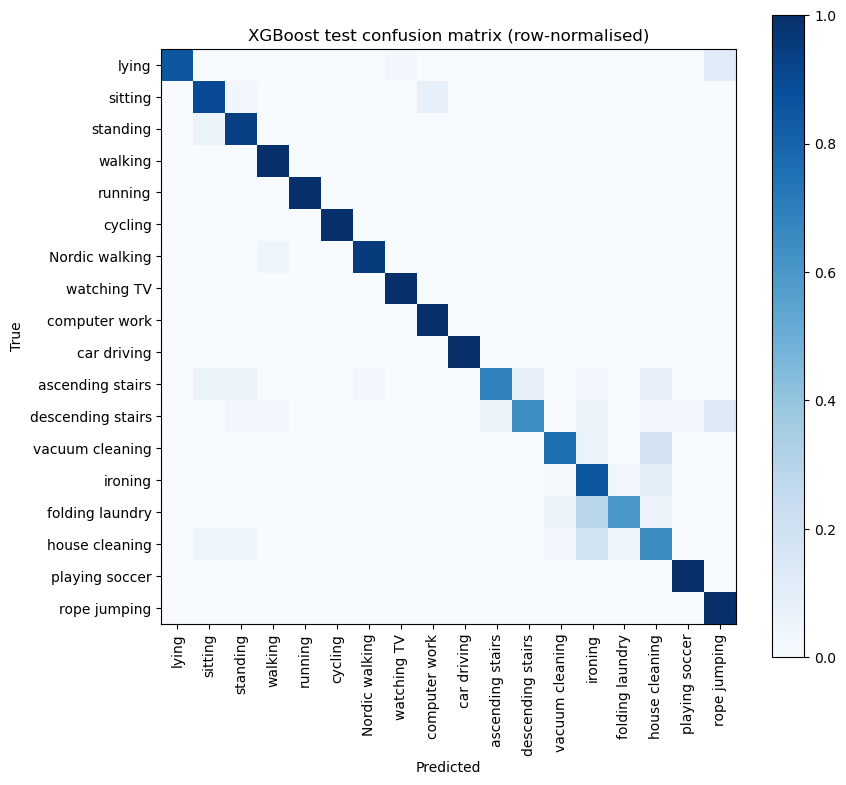

In [47]:
import matplotlib.pyplot as plt

cm = np.array(metrics["confusion_matrix"])
cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
names = [class_name(i) for i in CLASSES]
ax.set_xticks(range(K)); ax.set_xticklabels(names, rotation=90)
ax.set_yticks(range(K)); ax.set_yticklabels(names)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("XGBoost test confusion matrix (row-normalised)")
fig.colorbar(im); plt.tight_layout(); plt.show()

### Predictions file from the post-process step

In [48]:
pb_, pk_ = split_key(eval_info["predictions_uri"])
preds = pd.read_parquet(io.BytesIO(s3.get_object(Bucket=pb_, Key=pk_)["Body"].read()))
n_prod = len(read_parquet("production.parquet"))

assert len(preds) == n_prod, f"predictions rows {len(preds)} != production split rows {n_prod}"

print(len(preds), "predictions |", eval_info["predictions_uri"])
print(preds["activity_name"].value_counts().to_string())
print(preds["intensity"].value_counts().to_string())

4156 predictions | s3://pamap2-har-887757489409-us-east-1/models/pipeline/predictions/jlqa6fgd20cq/predictions.parquet
activity_name
computer work        485
ironing              451
walking              375
standing             368
lying                281
vacuum cleaning      279
Nordic walking       265
house cleaning       247
cycling              232
sitting              215
ascending stairs     166
descending stairs    150
running              134
watching TV          125
folding laundry       98
car driving           96
playing soccer        96
rope jumping          93
intensity
light       2119
moderate    1283
vigorous     754


### Lineage

In [49]:
try:
    from sagemaker.lineage.visualizer import LineageTableVisualizer
    viz = LineageTableVisualizer(sm_session)
    for s in reversed(execution.list_steps()):
        print("\n", s["StepName"])
        display(viz.show(pipeline_execution_step=s))
except Exception as e:
    print("Lineage not available:", e)


 PreprocessSplits


,Name/Source,Direction,Type,Association Type,Lineage Type
0,s3://...72ec3a90845eca79f5154d5a42/preprocess.py,Input,DataSet,ContributedTo,artifact
1,s3://...-887757489409-us-east-1/features/splits/,Input,DataSet,ContributedTo,artifact
2,68331...com/sagemaker-scikit-learn:1.2-1-cpu-py3,Input,Image,ContributedTo,artifact
3,s3://...s/pipeline/preprocess/jlqa6fgd20cq/batch,Output,DataSet,Produced,artifact
4,s3://...ls/pipeline/preprocess/jlqa6fgd20cq/test,Output,DataSet,Produced,artifact
5,s3://...eline/preprocess/jlqa6fgd20cq/validation,Output,DataSet,Produced,artifact
6,s3://...s/pipeline/preprocess/jlqa6fgd20cq/train,Output,DataSet,Produced,artifact



 TrainModel


,Name/Source,Direction,Type,Association Type,Lineage Type
0,s3://...eline/preprocess/jlqa6fgd20cq/validation,Input,DataSet,ContributedTo,artifact
1,s3://...s/pipeline/preprocess/jlqa6fgd20cq/train,Input,DataSet,ContributedTo,artifact
2,68331...-1.amazonaws.com/sagemaker-xgboost:1.7-1,Input,Image,ContributedTo,artifact
3,s3://...rainModel-cdHcpw9QWP/output/model.tar.gz,Output,Model,Produced,artifact



 EvaluateModel


...

None


 BatchTransform


,Name/Source,Direction,Type,Association Type,Lineage Type
0,s3://...rainModel-cdHcpw9QWP/output/model.tar.gz,Input,Model,ContributedTo,artifact
1,68331...-1.amazonaws.com/sagemaker-xgboost:1.7-1,Input,Image,ContributedTo,artifact
2,s3://...s/pipeline/preprocess/jlqa6fgd20cq/batch,Input,DataSet,ContributedTo,artifact
3,s3://...s/pipeline/transform-output/jlqa6fgd20cq,Output,DataSet,Produced,artifact



 PostProcessPredictions


,Name/Source,Direction,Type,Association Type,Lineage Type
0,s3://...4778c55b1deeddfe1fd6429f8/postprocess.py,Input,DataSet,ContributedTo,artifact
1,s3://...odels/pipeline/config/activity_meta.json,Input,DataSet,ContributedTo,artifact
2,s3://...-887757489409-us-east-1/features/splits/,Input,DataSet,ContributedTo,artifact
3,s3://...s/pipeline/transform-output/jlqa6fgd20cq,Input,DataSet,ContributedTo,artifact
4,68331...com/sagemaker-scikit-learn:1.2-1-cpu-py3,Input,Image,ContributedTo,artifact
5,s3://...models/pipeline/predictions/jlqa6fgd20cq,Output,DataSet,Produced,artifact


### Parametrized re-execution
`RUN_FAIL_DEMO = True` re-runs the pipeline with `MacroF1Threshold=0.999`, which should end in the `FailStep` and register nothing. The stable reports are not touched. Approval stays a human decision: override `ModelApprovalStatus` deliberately if needed.

In [50]:
RUN_FAIL_DEMO = True
if RUN_FAIL_DEMO:
    demo = pipeline.start(parameters={"MacroF1Threshold": 0.999})
    try:
        demo.wait(delay=30, max_attempts=240)
    except Exception as e:
        print("Expected gate failure:", e)
    print("Status:", demo.describe()["PipelineExecutionStatus"])
    display(pd.DataFrame([{"step": s["StepName"], "status": s["StepStatus"]} for s in reversed(demo.list_steps())]))
else:
    print("RUN_FAIL_DEMO is False - no second execution started.")

INFO:sagemaker.telemetry.telemetry_logging:SageMaker Python SDK will collect telemetry to help us better understand our user's needs, diagnose issues, and deliver additional features.
To opt out of telemetry, please disable via TelemetryOptOut parameter in SDK defaults config. For more information, refer to https://sagemaker.readthedocs.io/en/stable/overview.html#configuring-and-using-defaults-with-the-sagemaker-python-sdk.


Expected gate failure: Waiter PipelineExecutionComplete failed: Waiter encountered a terminal failure state: For expression "PipelineExecutionStatus" we matched expected path: "Failed"
Status: Failed


,step,status
0,PreprocessSplits,Succeeded
1,TrainModel,Succeeded
2,EvaluateModel,Succeeded
3,CheckMacroF1,Succeeded
4,MacroF1BelowThreshold,Failed


The pipeline gate only checks test macro-F1; batch transform and post-processing already ran while the package was `PendingManualApproval`. With `APPROVE = False` (the default) the approval cell only prints a message and nothing is approved. Setting `APPROVE = True` and running the next cell marks the model package `Approved` in the registry; re-run the model card afterwards to reflect it.

In [55]:
APPROVE = True 

In [56]:
if not APPROVE:
    print("APPROVE is False - model package NOT approved: " + train_info["model_package_arn"] + chr(10) +
          "Review the comparison above, set APPROVE = True and re-run this cell to approve.")
else:
    if not cmp["better"]:
        print("!" * 70 + chr(10) + "WARNING: XGBoost did NOT beat the benchmark on test macro-F1. Approving anyway (no auto-block)." + chr(10) + "!" * 70)
    sm.update_model_package(ModelPackageArn=train_info["model_package_arn"], ModelApprovalStatus="Approved",
                            ApprovalDescription="Approved manually after benchmark comparison")
    print("Approved:", train_info["model_package_arn"])

Approved: arn:aws:sagemaker:us-east-1:887757489409:model-package/pamap2-har-xgboost/2


## Model card

Creates (or updates) one SageMaker Model Card, `pamap2-har-xgboost-card`, for the registered XGBoost model. Overview, intended uses, business details, training details, evaluation details and additional information are filled from the real training job, model package and the S3 evaluation reports; the card status mirrors the registry (`Approved` when the package is Approved, otherwise `Draft`). View it in SageMaker Studio under Governance > Model cards.

In [57]:
from botocore.exceptions import ClientError
from sagemaker.model_card import (
    ModelCard, ModelOverview, IntendedUses, BusinessDetails, TrainingDetails, EvaluationJob,
    MetricGroup, Metric, AdditionalInformation, ObjectiveFunction, Function, HyperParameter,
    Environment, ModelCardStatusEnum, RiskRatingEnum, ObjectiveFunctionEnum, FacetEnum, MetricTypeEnum)
from src.pamap2.model_card import card_text, eval_metric_groups

# Report data is re-read from S3 / live SageMaker objects; the setup cells at the top (cfg, read_json, sm, sm_session, ...) must have been run.
T = card_text()
train_info = read_json(REPORTS + "xgboost_training.json")
eval_info = read_json(REPORTS + "xgboost_eval.json")
bench_test = read_json(REPORTS + "benchmark.json")["test_tree"]
card_pkg_arn = eval_info["model_package_arn"]
if train_info["model_package_arn"] != card_pkg_arn:
    raise RuntimeError("xgboost_training.json and xgboost_eval.json describe different model packages. "
                       "Re-run the publish cell of the pipeline section, then this cell.")
card_names = {int(i): ACTIVITY_NAMES[a] for i, a in eval_info["label_map"].items()}
pkg_desc = sm.describe_model_package(ModelPackageName=card_pkg_arn)
approval = pkg_desc["ModelApprovalStatus"]
card_status = ModelCardStatusEnum.APPROVED if approval == "Approved" else ModelCardStatusEnum.DRAFT   # mirrors the registry
job_name = train_info["training_job"]
job_desc = sm.describe_training_job(TrainingJobName=job_name)

# Model overview
overview = ModelOverview(
    model_id=card_pkg_arn, model_name=cfg["model_package_group"], model_description=T["model_description"],
    model_version=int(pkg_desc["ModelPackageVersion"]), problem_type="Multiclass Classification",
    algorithm_type=f"XGBoost (SageMaker built-in {cfg['xgboost_version']})",
    model_creator="Nishchal", model_owner="Nishchal", model_artifact=[train_info["model_data"]],
    inference_environment=Environment(container_image=[train_info["image_uri"]]))

# Intended uses and business details (stakeholders / line of business left empty on purpose)
uses = IntendedUses(
    purpose_of_model=T["purpose_of_model"], intended_uses=T["intended_uses"],
    factors_affecting_model_efficiency=T["factors_affecting_model_efficiency"],
    risk_rating=RiskRatingEnum.MEDIUM, explanations_for_risk_rating=T["explanations_for_risk_rating"])
business = BusinessDetails(business_problem=T["business_problem"])

# Training details: job ARN, image, metrics and hyperparameters are filled from the real training job
training = TrainingDetails.from_training_job_name(
    job_name, sagemaker_session=sm_session,
    objective_function=ObjectiveFunction(
        function=Function(function=ObjectiveFunctionEnum.MINIMIZE, facet=FacetEnum.LOSS,
                          condition="multiclass log loss (mlogloss) on the validation split"),
        notes="multi:softprob; early stopping on validation mlogloss"),
    training_observations=T["training_observations"])
tj = training.training_job_details
tj.training_datasets = [c["DataSource"]["S3DataSource"]["S3Uri"] for c in job_desc["InputDataConfig"]]
tj.user_provided_hyper_parameters = [
    HyperParameter(name="feature_count", value=str(len(FEATURES))),
    HyperParameter(name="class_count", value=str(len(card_names))),
    HyperParameter(name="split_scheme", value="chronological 40/10/10/40 per subject and activity, 1-window gap")]

# Evaluation details: one evaluation job with three metric groups
GROUP_NAMES = {"headline": "Headline (test split)", "per_class": "Per-class (test split)",
               "confusion_matrix": "Confusion matrix (test split)"}
groups = eval_metric_groups(eval_info, bench_test, card_names)
metric_groups = [
    MetricGroup(name=GROUP_NAMES[g], metric_data=[Metric(**{**m, "type": MetricTypeEnum(m["type"])}) for m in ms])
    for g, ms in groups.items()]
evaluation = EvaluationJob(
    name="Pipeline evaluation step (test split)", evaluation_observation=T["evaluation_observation"],
    datasets=[SPLITS + "test.parquet", eval_info["test_predictions_uri"]],
    metadata={"eval_report": REPORTS + "xgboost_eval.json", "evaluation_output": eval_info["evaluation_uri"],
              "predictions": eval_info["predictions_uri"], "benchmark_report": REPORTS + "benchmark.json"},
    metric_groups=metric_groups)

# Additional information
extra = AdditionalInformation(
    ethical_considerations=T["ethical_considerations"],
    caveats_and_recommendations=T["caveats_and_recommendations"],
    custom_details={"model_package_arn": card_pkg_arn, "pipeline_execution_arn": str(eval_info.get("pipeline_execution_arn")), "model_package_group": cfg["model_package_group"],
                    "approval_status": approval, "eval_report": REPORTS + "xgboost_eval.json",
                    "benchmark_report": REPORTS + "benchmark.json",
                    "debugger_artifacts": str(train_info.get("debugger_artifacts")),
                    "feature_group": cfg["feature_group"]})
sections = dict(model_overview=overview, intended_uses=uses, business_details=business,
                training_details=training, evaluation_details=[evaluation], additional_information=extra)

card_name = cfg["model_card"]
try:
    existing = sm.describe_model_card(ModelCardName=card_name)
except ClientError as e:
    if e.response["Error"]["Code"] not in ("ResourceNotFound", "ResourceNotFoundException"):
        raise
    existing = None
if existing is None:
    card = ModelCard(name=card_name, status=card_status, sagemaker_session=sm_session, **sections)
    card.create()
    action = "created"
else:
    if existing["ModelCardStatus"] == "Archived":
        raise RuntimeError(f"Model card {card_name} is Archived and cannot be updated. "
                           "Delete it (run 5_teardown.ipynb or sm.delete_model_card) and re-run this cell.")
    card = ModelCard.load(card_name, sagemaker_session=sm_session)
    card.status = card_status
    for attr, value in sections.items():
        setattr(card, attr, value)
    card.update()
    action = "updated"

d = sm.describe_model_card(ModelCardName=card_name)
print(f"Model card {action}: {d['ModelCardName']} | version {d['ModelCardVersion']} | status {d['ModelCardStatus']}")
print("ARN:", d["ModelCardArn"])
content = json.loads(d["Content"])
display(pd.DataFrame([
    {"section": s, "filled": len(v) if isinstance(v, list) else sum(1 for x in v.values() if x not in (None, "", [], {}))}
    for s, v in content.items()]))

/opt/conda/lib/python3.12/site-packages/sagemaker/model_card/model_card.py:1437: SageMakerV2DeprecationWarning: ModelCard is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use the model card resources under sagemaker.core.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
INFO:sagemaker.model_card.model_card:Creating model card with name: pamap2-har-xgboost-card


Model card created: pamap2-har-xgboost-card | version 1 | status Approved
ARN: arn:aws:sagemaker:us-east-1:887757489409:model-card/pamap2-har-xgboost-card


,section,filled
0,model_overview,10
1,intended_uses,5
2,business_details,1
3,training_details,3
4,evaluation_details,1
5,additional_information,3


### Confirm nothing is left running

In [58]:
print("Endpoints:", [e["EndpointName"] for e in sm.list_endpoints()["Endpoints"]])
print("Transform jobs in progress:", len(sm.list_transform_jobs(StatusEquals="InProgress")["TransformJobSummaries"]))
try:
    running = [e["PipelineExecutionArn"] for e in sm.list_pipeline_executions(PipelineName=cfg["pipeline_name"])["PipelineExecutionSummaries"]
               if e["PipelineExecutionStatus"] == "Executing"]
except sm.exceptions.ResourceNotFound:
    running = []
print("Pipeline executions in progress:", running)

Endpoints: []
Transform jobs in progress: 0
Pipeline executions in progress: []
